# **Forecasting Credit Worthiness and Client Characteristics for a Banking Debit Card Case, with SHAP Explainability for Model Interpretability and Input Data Optimization Based on Fixed KPIs**

*The project develops a model for predicting customer creditworthiness and supporting credit card issuance decisions.*

The model shows **strong predictive performance**, accurately identifying the two target classes:

* **0** - Lack of creditworthiness
* **1** - Presence of creditworthiness

A good balance is achieved between **credit risk management** and the ability to **identify areas of positive opportunity** for product offering.

**Model optimization led to a significant improvement in predicting class 0, strengthening the conservative approach to risk management.**
Through parameter balancing, there is a slight predominance among residual errors of **false negatives** — that is, individuals with borderline scores who are considered ineligible but are actually creditworthy — over **false positives**, meaning those who receive a credit card despite not meeting the requirements, who are therefore **less frequent**.

To understand the logic behind the model’s behavior, **explanatory analyses on the data variables were conducted, integrating the preliminary EDA (Exploratory Data Analysis) phase via Pearson with an in-depth model functioning analysis based on SHAP**.

The analyses highlighted three key dimensions:

- The **most relevant variables** are Annual income, Age, and Employment seniority, showing full alignment between linear correlation (Pearson) and model impact (SHAP).  
  These factors clearly identify profiles with higher credit reliability, enabling the calibration of parameters for **pre-approval policies**, **targeted operational thresholds**, and **targeting strategies for virtuous segments**.

- **Variable interactions**, revealed through SHAP Dependence Plots, expose non-linear threshold logic invisible to traditional statistical analysis.  
  Income has a positive effect only beyond certain levels, and it is amplified by synergy with the other two significant variables: Age and Employment seniority (measured in days employed).  
  These insights allow for the construction of **more precise and personalized decision rules**, with potential impact on segmentation by age group, adjustment of income thresholds based on life cycle, and credit marketing strategies to differentiate conditions and offers based on the combined age-income profile.

- A **possible systematic bias** emerged: younger profiles or those with discontinuous employment tend to be penalized, even when reporting incomes comparable to other targets.  
  This risk of indirect bias could reduce the inclusiveness of the model and hinder access to credit for potentially creditworthy customers.  
  An intervention could be considered on two fronts:
  - a **critical review of historical data** used in training
  - a possible **enrichment of input variables**, to better represent vulnerable profiles and support their inclusion in the scoring process.

The joint use of both techniques enabled a perspective that is useful not only for the **understanding of predictive logic**, but also for the **future optimization of the model**, through **hyperparameter refinement** and **improvement of input data**, guiding **transparent, personalized, and strategically effective operational decisions**.


---

## **Data Description**

Anonymized customer data is available, with the following features:

| Column Name           | Description |
|------------------------|-------------|
| `ID`                  | Customer identification number |
| `CODE_GENDER`         | Customer gender |
| `FLAG_OWN_CAR`        | Indicator of car ownership |
| `FLAG_OWN_REALTY`     | Indicator of home ownership |
| `CNT_CHILDREN`        | Number of children |
| `AMT_INCOME_TOTAL`    | Annual income |
| `NAME_INCOME_TYPE`    | Type of income |
| `NAME_EDUCATION_TYPE` | Education level |
| `NAME_FAMILY_STATUS`  | Marital status |
| `NAME_HOUSING_TYPE`   | Type of housing contract |
| `DAYS_BIRTH`          | Number of days since birth |
| `DAYS_EMPLOYED`       | Number of days since employment (positive values indicate days unemployed) |
| `FLAG_MOBIL`          | Indicator of having a mobile phone number |
| `FLAG_WORK_PHONE`     | Indicator of having a work phone number |
| `FLAG_PHONE`          | Indicator of having a phone number |
| `FLAG_EMAIL`          | Indicator of having an email address |
| `OCCUPATION_TYPE`     | Type of occupation |
| `CNT_FAM_MEMBERS`     | Number of family members |
| `TARGET`              | Creditworthiness target: `1` if high credit reliability (consistent installment payment), `0` otherwise |


In [ ]:
import pandas as pd
import numpy as np

# Data-preprocessing
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Pipeline and composer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from scipy.stats import ks_2samp, chi2_contingency
from sklearn.feature_selection import f_classif
from imblearn.under_sampling import RandomUnderSampler

# Validation
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.metrics import classification_report, accuracy_score, confusion_matrix

# Model
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, export_graphviz
import graphviz
from imblearn.under_sampling import RandomUnderSampler

# Visualization
import seaborn as sns
import matplotlib.pyplot as plt


EDA - EXPLORATORY DATA ANALYSIS

In [ ]:
url = "https://proai-datasets.s3.eu-west-3.amazonaws.com/credit_scoring.csv"
df = pd.read_csv(url, index_col=0)

df.head()

,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,FLAG_MOBIL,FLAG_WORK_PHONE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,TARGET
ID,,,,,,,,,,,,,,,,,,
5008804,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005.0,-4542.0,1.0,1.0,0.0,0.0,NaN,2.0,0
5008805,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005.0,-4542.0,1.0,1.0,0.0,0.0,NaN,2.0,0
5008806,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474.0,-1134.0,1.0,0.0,0.0,0.0,Security staff,2.0,0
5008808,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110.0,-3051.0,1.0,0.0,1.0,1.0,Sales staff,1.0,1
5008809,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110.0,-3051.0,1.0,0.0,1.0,1.0,Sales staff,1.0,1


In [ ]:
x = df.drop("TARGET", axis=1)
y = df["TARGET"]

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 338427 entries, 5008804 to 6392180
Data columns (total 18 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   CODE_GENDER          338427 non-null  object 
 1   FLAG_OWN_CAR         338427 non-null  object 
 2   FLAG_OWN_REALTY      338427 non-null  object 
 3   CNT_CHILDREN         338427 non-null  int64  
 4   AMT_INCOME_TOTAL     338427 non-null  float64
 5   NAME_INCOME_TYPE     338427 non-null  object 
 6   NAME_EDUCATION_TYPE  338427 non-null  object 
 7   NAME_FAMILY_STATUS   338426 non-null  object 
 8   NAME_HOUSING_TYPE    338426 non-null  object 
 9   DAYS_BIRTH           338426 non-null  float64
 10  DAYS_EMPLOYED        338426 non-null  float64
 11  FLAG_MOBIL           338426 non-null  float64
 12  FLAG_WORK_PHONE      338426 non-null  float64
 13  FLAG_PHONE           338426 non-null  float64
 14  FLAG_EMAIL           338426 non-null  float64
 15  OCCUPATION_TYPE

In [ ]:
# Identify quantitative features if the dtype of the column is float64
numerical_features = [col for col in x.columns if x[col].dtype =='float64']

# Identify categorical features
cat_features = [col for col in x.columns if x[col].dtype =='object']

# Display the number of each type
len(numerical_features), len(cat_features)

(8, 8)

So we have 8 numerical features and 8 categorical features

In [ ]:
print(df.isna().sum())

CODE_GENDER                 0
FLAG_OWN_CAR                0
FLAG_OWN_REALTY             0
CNT_CHILDREN                0
AMT_INCOME_TOTAL            0
NAME_INCOME_TYPE            0
NAME_EDUCATION_TYPE         0
NAME_FAMILY_STATUS          1
NAME_HOUSING_TYPE           1
DAYS_BIRTH                  1
DAYS_EMPLOYED               1
FLAG_MOBIL                  1
FLAG_WORK_PHONE             1
FLAG_PHONE                  1
FLAG_EMAIL                  1
OCCUPATION_TYPE        103342
CNT_FAM_MEMBERS             1
TARGET                      0
dtype: int64


### Dataset Cleaning

1. **`OCCUPATION_TYPE` Column**
   The variable has 10,334 missing entries. Considering the high number of null values and the limited informativeness of the variable with respect to the target, the column is removed from the dataset.

2. **Removal of Low-Informative Variables**
   The following binary variables are not relevant for modeling purposes and are therefore removed:

   * `FLAG_MOBIL`
   * `FLAG_WORK_PHONE`
   * `FLAG_PHONE`
   * `FLAG_EMAIL`

3. **Handling Missing Values**

   * **Quantitative Variables**:
     For the continuous variables:

     ```
     ['DAYS_BIRTH', 'DAYS_EMPLOYED', 'CNT_FAM_MEMBERS']
     ```

     missing values are imputed with the median of the respective variable’s distribution.

   * **Categorical Variables**:
     For the categorical variables:

     ```
     ['NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE']
     ```

     missing values are imputed with the mode (most frequent value) of the variable.


In [ ]:
# Remove unnecessary columns: ID, OCCUPATION_TYPE, FLAG_MOBIL, FLAG_WORK_PHONE, FLAG_PHONE, FLAG_EMAIL

df = pd.read_csv(url, index_col=0)

df.reset_index(inplace=True)

df = df.drop(columns=["ID"])

df.drop(columns=['OCCUPATION_TYPE', 'FLAG_MOBIL', 'FLAG_WORK_PHONE', 'FLAG_PHONE', 'FLAG_EMAIL'], inplace=True)

df.head()

,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,CNT_FAM_MEMBERS,TARGET
0,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005.0,-4542.0,2.0,0
1,M,Y,Y,0,427500.0,Working,Higher education,Civil marriage,Rented apartment,-12005.0,-4542.0,2.0,0
2,M,Y,Y,0,112500.0,Working,Secondary / secondary special,Married,House / apartment,-21474.0,-1134.0,2.0,0
3,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110.0,-3051.0,1.0,1
4,F,N,Y,0,270000.0,Commercial associate,Secondary / secondary special,Single / not married,House / apartment,-19110.0,-3051.0,1.0,1


Verify the balance of dummy features

In [ ]:
counts = df["CODE_GENDER"].value_counts()
counts

CODE_GENDER
F    227916
M    110511
Name: count, dtype: int64

In [ ]:
counts = df["FLAG_OWN_CAR"].value_counts()
counts

FLAG_OWN_CAR
N    213196
Y    125231
Name: count, dtype: int64

In [ ]:
counts = df["FLAG_OWN_REALTY"].value_counts()
counts

FLAG_OWN_REALTY
Y    231307
N    107120
Name: count, dtype: int64

In [ ]:
counts = df["NAME_EDUCATION_TYPE"].value_counts()
counts

NAME_EDUCATION_TYPE
Secondary / secondary special    232568
Higher education                  91062
Incomplete higher                 11387
Lower secondary                    3177
Academic degree                     232
Secondary / se                        1
Name: count, dtype: int64

In [ ]:
counts = df["NAME_FAMILY_STATUS"].value_counts()
counts

NAME_FAMILY_STATUS
Married                 231494
Single / not married     42509
Civil marriage           28516
Separated                20809
Widow                    15098
Name: count, dtype: int64

In [ ]:
counts = df["NAME_HOUSING_TYPE"].value_counts()
counts

NAME_HOUSING_TYPE
House / apartment      304410
With parents            14625
Municipal apartment     10819
Rented apartment         4442
Office apartment         2968
Co-op apartment          1162
Name: count, dtype: int64

In [ ]:
counts = df["TARGET"].value_counts()
counts

TARGET
0    308705
1     29722
Name: count, dtype: int64

In [ ]:
percentages = df["TARGET"].value_counts(normalize=True) * 100
percentages_formatted = percentages.apply(lambda x: f"{x:.2f}%")
percentages_formatted

TARGET
0    91.22%
1     8.78%
Name: proportion, dtype: object

The features appear generally well-balanced. However, the target seems very imbalanced (0: 91.22%; 1: 8.78%).


Transformation of features

In [ ]:
# Observe the composition of the data set
print(df.head())

  CODE_GENDER FLAG_OWN_CAR FLAG_OWN_REALTY  CNT_CHILDREN  AMT_INCOME_TOTAL  \
0           M            Y               Y             0          427500.0   
1           M            Y               Y             0          427500.0   
2           M            Y               Y             0          112500.0   
3           F            N               Y             0          270000.0   
4           F            N               Y             0          270000.0   

       NAME_INCOME_TYPE            NAME_EDUCATION_TYPE    NAME_FAMILY_STATUS  \
0               Working               Higher education        Civil marriage   
1               Working               Higher education        Civil marriage   
2               Working  Secondary / secondary special               Married   
3  Commercial associate  Secondary / secondary special  Single / not married   
4  Commercial associate  Secondary / secondary special  Single / not married   

   NAME_HOUSING_TYPE  DAYS_BIRTH  DAYS_EMPLOYED  C

Ecco la traduzione fedele con la stessa formattazione:

### Feature Engineering

1. **Transformation of Non-Binary Categorical Variables via One-Hot Encoding**
   The following variables, representing non-ordinal categories, are transformed into binary vectors:

   * `NAME_INCOME_TYPE` (income source)
   * `NAME_FAMILY_STATUS` (marital status)
   * `NAME_HOUSING_TYPE` (type of rental contract)

2. **Encoding of Qualitative Variables into Numerical Values**
   The following variables, qualitative in nature but with limited cardinality, are converted into numerical representations:

   * `NAME_EDUCATION_TYPE` (level of education)
   * `CODE_GENDER` (customer gender)
   * `FLAG_OWN_CAR` (car ownership)
   * `FLAG_OWN_REALTY` (real estate ownership)

One Hot Encoding

In [ ]:
# NAME_INCOME_TYPE
income_type_labels = df['NAME_INCOME_TYPE'].unique()
print(income_type_labels)


['Working' 'Commercial associate' 'Pensioner' 'State servant' 'Student']


In [ ]:
df = pd.get_dummies(df, columns=['NAME_INCOME_TYPE'], dtype=int)

In [ ]:
# NAME_FAMILY_STATUS
income_type_labels = df['NAME_FAMILY_STATUS'].unique()
print(income_type_labels)


['Civil marriage' 'Married' 'Single / not married' 'Separated' 'Widow' nan]


In [ ]:
df = pd.get_dummies(df, columns=['NAME_FAMILY_STATUS'], dtype=int)

In [ ]:
# NAME_HOUSING_TYPE
income_type_labels = df['NAME_HOUSING_TYPE'].unique()
print(income_type_labels)

['Rented apartment' 'House / apartment' 'Municipal apartment'
 'With parents' 'Co-op apartment' 'Office apartment' nan]


In [ ]:
df = pd.get_dummies(df, columns=['NAME_HOUSING_TYPE'], dtype=int)

In [ ]:
column_names = df.columns.tolist()

# Print the names of the new columns after transformations
for col in column_names:
    print(col)

CODE_GENDER
FLAG_OWN_CAR
FLAG_OWN_REALTY
CNT_CHILDREN
AMT_INCOME_TOTAL
NAME_EDUCATION_TYPE
DAYS_BIRTH
DAYS_EMPLOYED
CNT_FAM_MEMBERS
TARGET
NAME_INCOME_TYPE_Commercial associate
NAME_INCOME_TYPE_Pensioner
NAME_INCOME_TYPE_State servant
NAME_INCOME_TYPE_Student
NAME_INCOME_TYPE_Working
NAME_FAMILY_STATUS_Civil marriage
NAME_FAMILY_STATUS_Married
NAME_FAMILY_STATUS_Separated
NAME_FAMILY_STATUS_Single / not married
NAME_FAMILY_STATUS_Widow
NAME_HOUSING_TYPE_Co-op apartment
NAME_HOUSING_TYPE_House / apartment
NAME_HOUSING_TYPE_Municipal apartment
NAME_HOUSING_TYPE_Office apartment
NAME_HOUSING_TYPE_Rented apartment
NAME_HOUSING_TYPE_With parents


Transformation of qualitative variables into numerical values

In [ ]:
# NAME_EDUCATION_TYPE
income_type_labels = df['NAME_EDUCATION_TYPE'].unique()
print(income_type_labels)

['Higher education' 'Secondary / secondary special' 'Incomplete higher'
 'Lower secondary' 'Academic degree' 'Secondary / se']


In [ ]:
# NAME_EDUCATION_TYPE
# Being an ordinal qualitative variable, we assign values 0, 1, 2, 3, 4, 5:
df['NAME_EDUCATION_TYPE'] = df['NAME_EDUCATION_TYPE'].astype(str).str.strip().str.capitalize()
size_mapping = {'Lower secondary':0, 'Secondary / se':1, 'Secondary / secondary special':2, 'Incomplete higher':3, 'Higher education':4, 'Academic degree':5}
df['NAME_EDUCATION_TYPE'] = df['NAME_EDUCATION_TYPE'].map(size_mapping)


In [ ]:
# CODE_GENDER
print(df['CODE_GENDER'].unique())

['M' 'F']


In [ ]:
df['CODE_GENDER'] = df['CODE_GENDER'].astype(str).str.strip().str.capitalize()
size_mapping = {'M': 1, 'F': 0}
df['CODE_GENDER'] = df['CODE_GENDER'].map(size_mapping)

In [ ]:
# FLAG_OWN_CAR
print(df['FLAG_OWN_CAR'].unique())

['Y' 'N']


In [ ]:
df['FLAG_OWN_CAR'] = df['FLAG_OWN_CAR'].astype(str).str.strip().str.capitalize()
size_mapping = {'Y': 1, 'N': 0}
df['FLAG_OWN_CAR'] = df['FLAG_OWN_CAR'].map(size_mapping)

In [ ]:
# FLAG_OWN_REALTY
print(df['FLAG_OWN_REALTY'].unique())

['Y' 'N']


In [ ]:
df['FLAG_OWN_REALTY'] = df['FLAG_OWN_REALTY'].astype(str).str.strip().str.capitalize()
size_mapping = {'Y': 1, 'N': 0}
df['FLAG_OWN_REALTY'] = df['FLAG_OWN_REALTY'].map(size_mapping)

In [ ]:
rows, columns = df.shape
print(f"[{rows} rows x {columns} columns]")

[338427 rows x 26 columns]


In [ ]:
# Check the data set after transformations
df.head()

,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,NAME_EDUCATION_TYPE,DAYS_BIRTH,DAYS_EMPLOYED,CNT_FAM_MEMBERS,TARGET,...,NAME_FAMILY_STATUS_Married,NAME_FAMILY_STATUS_Separated,NAME_FAMILY_STATUS_Single / not married,NAME_FAMILY_STATUS_Widow,NAME_HOUSING_TYPE_Co-op apartment,NAME_HOUSING_TYPE_House / apartment,NAME_HOUSING_TYPE_Municipal apartment,NAME_HOUSING_TYPE_Office apartment,NAME_HOUSING_TYPE_Rented apartment,NAME_HOUSING_TYPE_With parents
0,1,1,1,0,427500.0,4,-12005.0,-4542.0,2.0,0,...,0,0,0,0,0,0,0,0,1,0
1,1,1,1,0,427500.0,4,-12005.0,-4542.0,2.0,0,...,0,0,0,0,0,0,0,0,1,0
2,1,1,1,0,112500.0,2,-21474.0,-1134.0,2.0,0,...,1,0,0,0,0,1,0,0,0,0
3,0,0,1,0,270000.0,2,-19110.0,-3051.0,1.0,1,...,0,0,1,0,0,1,0,0,0,0
4,0,0,1,0,270000.0,2,-19110.0,-3051.0,1.0,1,...,0,0,1,0,0,1,0,0,0,0


Distribution analysis of observations

Summary of quantitative features

In [ ]:
columns_of_interest = ['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'DAYS_BIRTH', 'DAYS_EMPLOYED']

x_described = df[columns_of_interest].describe().transpose()

print(x_described)

                     count           mean            std      min       25%  \
CNT_CHILDREN      338427.0       0.428934       0.727990      0.0       0.0   
AMT_INCOME_TOTAL  338427.0  187654.340799  110674.689042  26100.0  121500.0   
DAYS_BIRTH        338426.0  -15998.249644    4180.240053 -25201.0  -19482.0   
DAYS_EMPLOYED     338426.0   60238.497163  138499.153147 -17531.0   -3116.0   

                       50%       75%        max  
CNT_CHILDREN           0.0       1.0       19.0  
AMT_INCOME_TOTAL  162000.0  225000.0  6750000.0  
DAYS_BIRTH        -15622.0  -12524.0    -7489.0  
DAYS_EMPLOYED      -1485.0    -380.0   365243.0  


The feature values appear to be distributed across different scales. This aspect poses particular issues because some variables fed into the model may dominate others.
We will address this with **Standardization** — mean 0 and standard deviation 1.
This technique brings the variables onto the same scale and makes them comparable, while preserving the relative differences between individual values within each variable.

Histograms for distribution plots

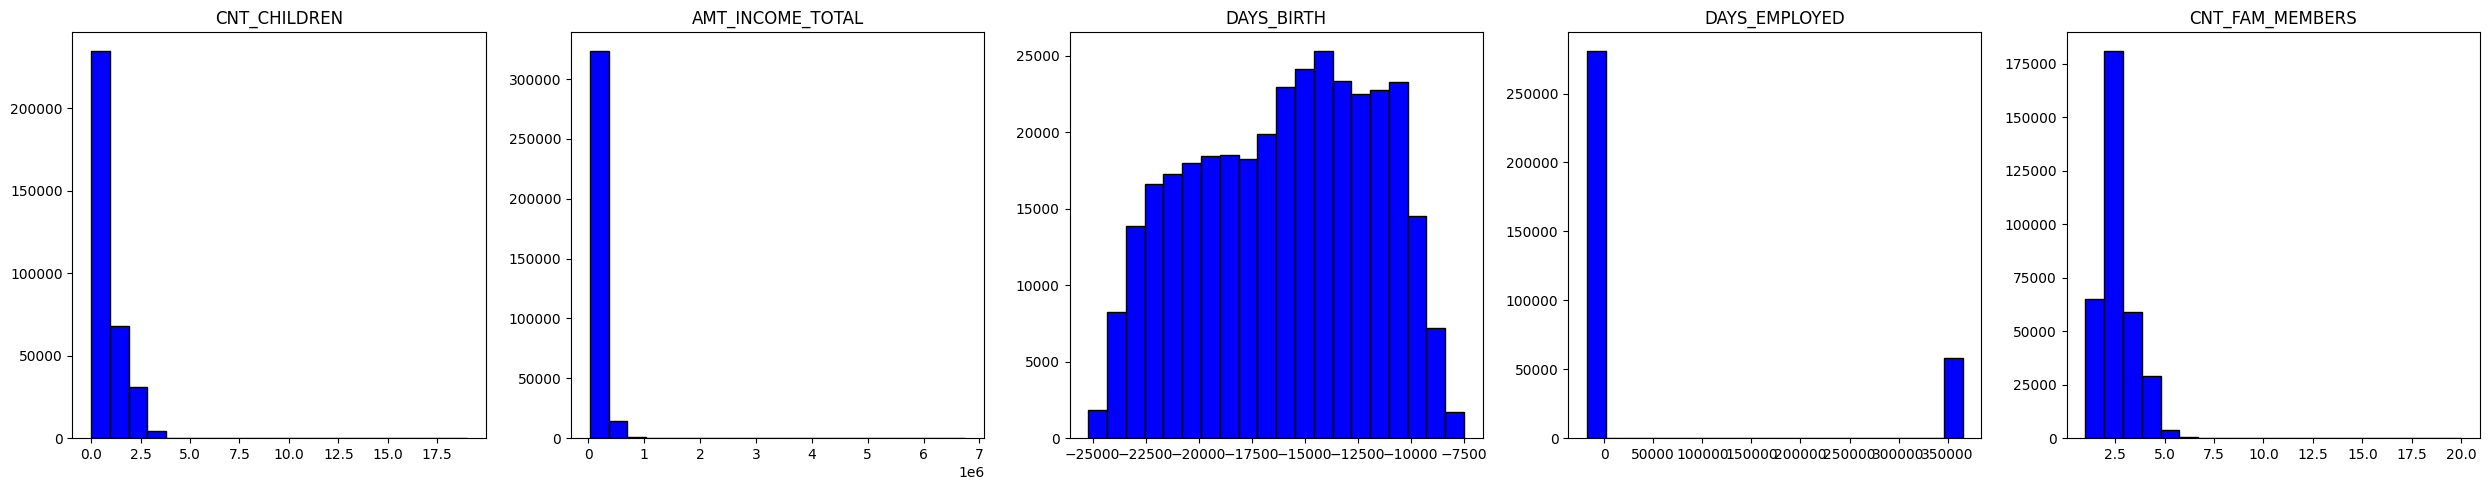

In [ ]:
columns = ['CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'CNT_FAM_MEMBERS']

fig, axes = plt.subplots(1, 5, figsize=(25, 5))
axes = axes.flatten()

for i, col in enumerate(columns):
    axes[i].hist(df[col], bins=20, color='blue', edgecolor='black')
    axes[i].set_title(col)

plt.tight_layout()
plt.show()


### Analysis of Quantitative Variable Distributions

The distribution of the **quantitative variables** examined shows marked **negative skewness** in the first two and the last charts, related to:

* `CNT_CHILDREN`
* `AMT_INCOME_TOTAL`
* `CNT_FAM_MEMBERS`

These variables exhibit a concentration of observations at low values, with long tails extending to the right.

The variable **`DAYS_BIRTH`**, shown in the third chart, instead displays an approximately **normal distribution**, although with mild skewness. The peak density lies between 10,000 and 15,000 days from birth, corresponding to an age range of approximately 27 to 41 years.

The distribution of **`DAYS_EMPLOYED`** reveals a clear structural anomaly: positive values represent unemployed individuals and correspond to a very high placeholder code, while negative values indicate actual days of employment. As such, the variable is highly distorted and difficult to interpret in its original form.

These asymmetries may impair the performance of statistical models and algorithms that assume symmetric variable distributions, particularly in linear models.

In light of this, a **logarithmic transformation** is applied to the continuous quantitative variables with strongly skewed distributions, in order to improve their statistical tractability and reduce the influence of extreme values.


Preprocessing activity following the histogram distribution analysis

In [ ]:
# Logarithmic transformation of AMT_INCOME
df['LOG_AMT_INCOME_TOTAL'] = np.log1p(df['AMT_INCOME_TOTAL'])

print(df[['AMT_INCOME_TOTAL', 'LOG_AMT_INCOME_TOTAL']])

        AMT_INCOME_TOTAL  LOG_AMT_INCOME_TOTAL
0               427500.0             12.965712
1               427500.0             12.965712
2               112500.0             11.630717
3               270000.0             12.506181
4               270000.0             12.506181
...                  ...                   ...
338422          157500.0             11.967187
338423          157500.0             11.967187
338424          157500.0             11.967187
338425          157500.0             11.967187
338426           67500.0             11.119898

[338427 rows x 2 columns]


In [ ]:
# DAY_EMPLOYED

# Create two new columns for DAYS_EMPLOYED: one for the employed and one for the unemployed with absolute values
df['DAYS_EMPLOYED_OCCUPIED'] = df['DAYS_EMPLOYED'].apply(lambda x: abs(x) if x < 0 else 0)
df['DAYS_EMPLOYED_UNEMPLOYED'] = df['DAYS_EMPLOYED'].apply(lambda x: abs(x) if x >= 0 else 0)

# Logarithmic transformation
df['LOG_DAYS_EMPLOYED_OCCUPIED'] = df['DAYS_EMPLOYED_OCCUPIED'].apply(lambda x: np.log1p(x) if x > 0 else 0)
df['LOG_DAYS_EMPLOYED_UNEMPLOYED'] = df['DAYS_EMPLOYED_UNEMPLOYED'].apply(lambda x: np.log1p(x) if x > 0 else 0)

print(df[['LOG_DAYS_EMPLOYED_OCCUPIED', 'LOG_DAYS_EMPLOYED_UNEMPLOYED']])

        LOG_DAYS_EMPLOYED_OCCUPIED  LOG_DAYS_EMPLOYED_UNEMPLOYED
0                         8.421343                      0.000000
1                         8.421343                      0.000000
2                         7.034388                      0.000000
3                         8.023552                      0.000000
4                         8.023552                      0.000000
...                            ...                           ...
338422                    0.000000                     12.808321
338423                    0.000000                     12.808321
338424                    0.000000                     12.808321
338425                    0.000000                     12.808321
338426                    0.000000                      0.000000

[338427 rows x 2 columns]


In [ ]:
# DAYS_BIRTH

# Create a new column that converts DAYS_BIRTH from days to years
df['YEARS_BIRTH'] = df['DAYS_BIRTH'] / -365

print(df[['DAYS_BIRTH', 'YEARS_BIRTH']])

        DAYS_BIRTH  YEARS_BIRTH
0         -12005.0    32.890411
1         -12005.0    32.890411
2         -21474.0    58.832877
3         -19110.0    52.356164
4         -19110.0    52.356164
...            ...          ...
338422    -23661.0    64.824658
338423    -23661.0    64.824658
338424    -23661.0    64.824658
338425    -23661.0    64.824658
338426         NaN          NaN

[338427 rows x 2 columns]


In [ ]:
# List of variables in the dataset
variabili = df.columns.tolist()

print(variabili)

['CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'NAME_EDUCATION_TYPE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'CNT_FAM_MEMBERS', 'TARGET', 'NAME_INCOME_TYPE_Commercial associate', 'NAME_INCOME_TYPE_Pensioner', 'NAME_INCOME_TYPE_State servant', 'NAME_INCOME_TYPE_Student', 'NAME_INCOME_TYPE_Working', 'NAME_FAMILY_STATUS_Civil marriage', 'NAME_FAMILY_STATUS_Married', 'NAME_FAMILY_STATUS_Separated', 'NAME_FAMILY_STATUS_Single / not married', 'NAME_FAMILY_STATUS_Widow', 'NAME_HOUSING_TYPE_Co-op apartment', 'NAME_HOUSING_TYPE_House / apartment', 'NAME_HOUSING_TYPE_Municipal apartment', 'NAME_HOUSING_TYPE_Office apartment', 'NAME_HOUSING_TYPE_Rented apartment', 'NAME_HOUSING_TYPE_With parents', 'LOG_AMT_INCOME_TOTAL', 'DAYS_EMPLOYED_OCCUPIED', 'DAYS_EMPLOYED_UNEMPLOYED', 'LOG_DAYS_EMPLOYED_OCCUPIED', 'LOG_DAYS_EMPLOYED_UNEMPLOYED', 'YEARS_BIRTH']


In [ ]:
# Clean up redundant columns after transformations
df.drop(columns=['AMT_INCOME_TOTAL', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_EMPLOYED_OCCUPIED', 'DAYS_EMPLOYED_UNEMPLOYED'], inplace=True)

# Rename the remaining columns
df.rename(columns={
    'LOG_AMT_INCOME_TOTAL': 'AMT_INCOME',
    'LOG_DAYS_EMPLOYED_OCCUPIED': 'DAYS_EMPLOYED',
    'LOG_DAYS_EMPLOYED_UNEMPLOYED': 'DAYS_NOT_EMPLOYED'
}, inplace=True)

print(df.head())


   CODE_GENDER  FLAG_OWN_CAR  FLAG_OWN_REALTY  CNT_CHILDREN  \
0            1             1                1             0   
1            1             1                1             0   
2            1             1                1             0   
3            0             0                1             0   
4            0             0                1             0   

   NAME_EDUCATION_TYPE  CNT_FAM_MEMBERS  TARGET  \
0                    4              2.0       0   
1                    4              2.0       0   
2                    2              2.0       0   
3                    2              1.0       1   
4                    2              1.0       1   

   NAME_INCOME_TYPE_Commercial associate  NAME_INCOME_TYPE_Pensioner  \
0                                      0                           0   
1                                      0                           0   
2                                      0                           0   
3                         

Correlation analysis between variables


To validate the selected model, it is important to maintain the proportion of observations belonging to the two classes even after splitting into training and validation/test sets. The target variable showed significant imbalance. To obtain two subsets of data where the percentage of observations belonging to class 0 and class 1 is approximately the same as in the original dataset, we incorporated the "stratify" parameter in "train_test_split".

In [ ]:
x = df.drop("TARGET", axis=1)
y = df["TARGET"]
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, stratify=y)

In [ ]:
# Combine x_train and y_train to calculate the correlation
train_df = x_train.copy()
train_df["TARGET"] = y_train

Pearson correlation index between variables: table and matrix


In [ ]:
# Calculate the correlation matrix
corr_matrix = train_df.corr()
corr_matrix

,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,NAME_EDUCATION_TYPE,CNT_FAM_MEMBERS,NAME_INCOME_TYPE_Commercial associate,NAME_INCOME_TYPE_Pensioner,NAME_INCOME_TYPE_State servant,NAME_INCOME_TYPE_Student,...,NAME_HOUSING_TYPE_House / apartment,NAME_HOUSING_TYPE_Municipal apartment,NAME_HOUSING_TYPE_Office apartment,NAME_HOUSING_TYPE_Rented apartment,NAME_HOUSING_TYPE_With parents,AMT_INCOME,DAYS_EMPLOYED,DAYS_NOT_EMPLOYED,YEARS_BIRTH,TARGET
CODE_GENDER,1.000000,0.346833,-0.043485,0.086790,-0.011472,0.115361,0.043387,-0.167227,-0.026497,0.000092,...,-0.051558,-0.012507,0.026050,0.030409,0.053348,0.211929,0.134798,-0.167227,-0.189200,0.015601
FLAG_OWN_CAR,0.346833,1.000000,-0.000350,0.115702,0.098487,0.157294,0.066654,-0.163706,0.007325,-0.002997,...,0.005072,-0.035644,0.015484,0.002193,0.010362,0.216266,0.149605,-0.163706,-0.162312,0.034078
FLAG_OWN_REALTY,-0.043485,-0.000350,1.000000,0.003038,-0.015788,0.008120,0.010513,0.069708,-0.027775,0.001015,...,0.191383,-0.108918,-0.035603,-0.057446,-0.139250,0.032111,-0.060944,0.069708,0.110960,0.028916
CNT_CHILDREN,0.086790,0.115702,0.003038,1.000000,0.036170,0.886546,0.029346,-0.242203,0.043690,-0.002563,...,-0.021448,-0.011477,0.017369,0.013439,0.021911,0.026560,0.219218,-0.242203,-0.350336,-0.091986
NAME_EDUCATION_TYPE,-0.011472,0.098487,-0.015788,0.036170,1.000000,0.025582,0.113531,-0.123995,0.111056,0.007331,...,-0.000618,-0.046408,0.017617,-0.008580,0.030226,0.237865,0.109864,-0.123995,-0.154928,0.032409
CNT_FAM_MEMBERS,0.115361,0.157294,0.008120,0.886546,0.025582,1.000000,0.025168,-0.234349,0.050750,-0.002878,...,0.012387,-0.021494,0.017167,0.003700,-0.012172,0.013099,0.221054,-0.234349,-0.307834,-0.078101
NAME_INCOME_TYPE_Commercial associate,0.043387,0.066654,0.010513,0.029346,0.113531,0.025168,1.000000,-0.248624,-0.165011,-0.003914,...,-0.018309,0.004132,-0.008421,0.008104,0.022646,0.191784,0.211774,-0.248624,-0.157822,0.061769
NAME_INCOME_TYPE_Pensioner,-0.167227,-0.163706,0.069708,-0.242203,-0.123995,-0.234349,-0.248624,1.000000,-0.135647,-0.003218,...,0.081593,0.003516,-0.021784,-0.036972,-0.088408,-0.190708,-0.947603,1.000000,0.618748,-0.140276
NAME_INCOME_TYPE_State servant,-0.026497,0.007325,-0.027775,0.043690,0.111056,0.050750,-0.165011,-0.135647,1.000000,-0.002136,...,-0.044734,0.026533,0.071437,-0.000906,0.010568,0.046414,0.167525,-0.135647,-0.065156,0.050045
NAME_INCOME_TYPE_Student,0.000092,-0.002997,0.001015,-0.002563,0.007331,-0.002878,-0.003914,-0.003218,-0.002136,1.000000,...,-0.007502,-0.001292,0.012052,0.004403,0.004324,-0.000605,0.003621,-0.003218,-0.002865,0.001983


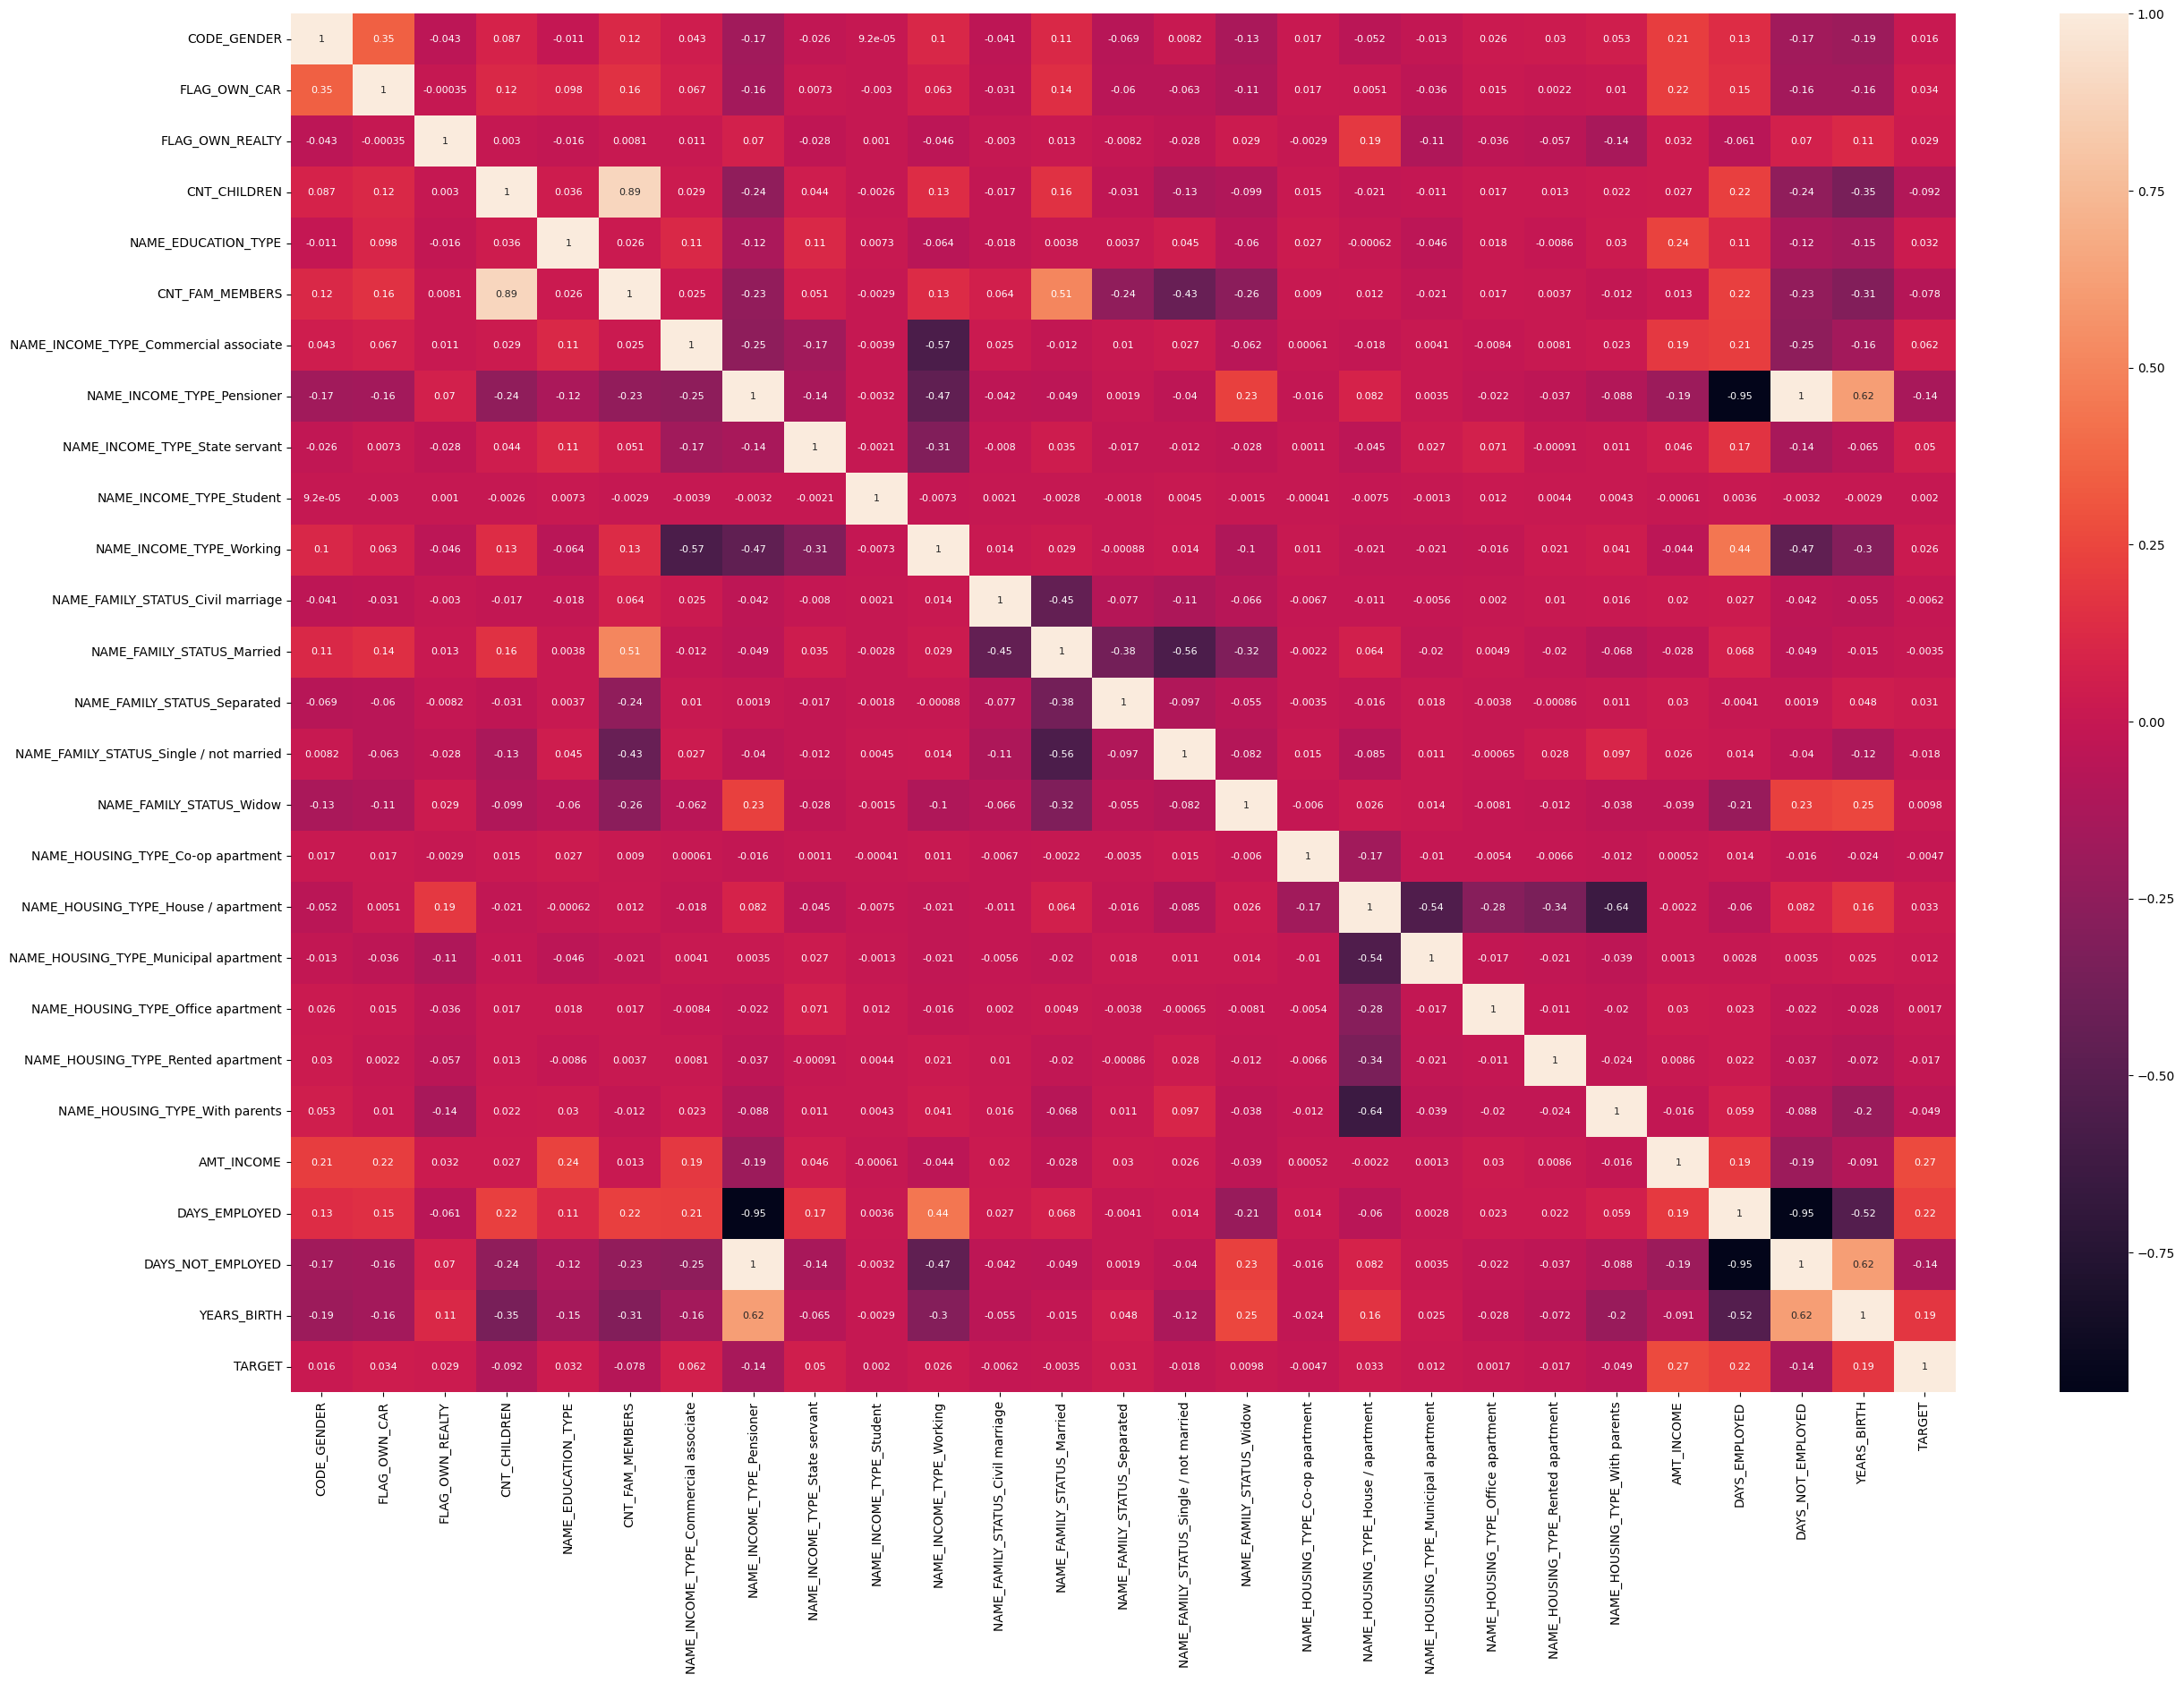

In [ ]:
# Visualize the correlation matrix
plt.figure(figsize=(30,20))
sns.heatmap(corr_matrix, annot=True, annot_kws={"size":8})
plt.show()

### Correlation Analysis Between Variables

The correlation analysis has a twofold objective:

1. To verify the **correlation between the independent variables and the target variable**, in order to identify features with predictive power.
2. To verify the **decorrelation among independent variables**, to reduce collinearity and improve model stability.

#### Correlation with the Target Variable

Pearson highlights the following 5 variables as most correlated with the TARGET:

* `AMT_INCOME` (annual income): 0.27 → positively correlated.
* `DAYS_EMPLOYED` (actual days of employment): 0.22 → positively correlated.
* `YEARS_BIRTH` (customer age): 0.18 → positively correlated.
* `DAYS_NOT_EMPLOYED` (days of unemployment): -0.14 → negatively correlated.
* `NAME_INCOME_TYPE_PENSIONER`: -0.14 → negatively correlated (retired clients tend to be less reliable).

#### Collinearity Between Variables (Decorrelation)

Using a threshold value of 0.70, the following high correlations between features are observed:

* `CNT_FAM_MEMBERS` and `CNT_CHILDREN`: 0.89
* `NAME_INCOME_TYPE_PENSIONER` and `DAYS_EMPLOYED`: -0.95

It is particularly notable that:

* `DAYS_EMPLOYED` (number of days since hiring)
* `NAME_INCOME_TYPE_PENSIONER` (income type “pensioner”)

are strongly correlated with each other (-0.95), and both are also correlated with the target variable (respectively 0.22 and -0.14).

To assess whether to proceed with **feature selection**, based on statistical relevance and informational redundancy, and to understand which of the two variables to retain, a **Chi-square test** can be performed on the relationship between each variable and the target.


**Chi-Square Test**

The test is particularly useful for comparing two categorical variables.
We use a contingency table to compare the frequency of observations for `DAYS_EMPLOYED` and `NAME_INCOME_TYPE_PENSIONER` with the Target in each interval.

We then apply the Chi-Square test to the contingency table.
Under the null hypothesis, there is no relationship between the two variables.
We reject the null hypothesis with a p-value threshold of <5%.

In [ ]:
#DAYS_EMPLOYED and TARGET
DAYS_EMPLOYED_discr = pd.cut(df['DAYS_EMPLOYED'], 10) # This function divides the data into 10 bins.
pd.crosstab(DAYS_EMPLOYED_discr,df['TARGET'])

TARGET,0,1
DAYS_EMPLOYED,,
"(-0.00977, 0.977]",57842,0
"(1.954, 2.932]",28,0
"(2.932, 3.909]",116,0
"(3.909, 4.886]",4160,0
"(4.886, 5.863]",20175,0
"(5.863, 6.84]",46600,0
"(6.84, 7.817]",88878,7384
"(7.817, 8.795]",76150,16104
"(8.795, 9.772]",14756,6234


In [ ]:
chi2_contingency(pd.crosstab(DAYS_EMPLOYED_discr,df['TARGET']))

Chi2ContingencyResult(statistic=32688.81856851804, pvalue=0.0, dof=8, expected_freq=array([[5.27620864e+04, 5.07991361e+03],
       [2.55409291e+01, 2.45907094e+00],
       [1.05812420e+02, 1.01875796e+01],
       [3.79465232e+03, 3.65347682e+02],
       [1.84031516e+04, 1.77184843e+03],
       [4.25074034e+04, 4.09259663e+03],
       [8.78078898e+04, 8.45411023e+03],
       [8.41518882e+04, 8.10211179e+03],
       [1.91465750e+04, 1.84342496e+03]]))

The function returns:

* Chi2: value of the Chi-Square test statistic.
* dof: degrees of freedom of the test.
* expected\_freq: frequency distribution assuming the two variables are independent.
* p-value: indicates whether the association is statistically significant.

The p-value is zero and allows us to reject the hypothesis of statistically independent distributions: we have verified the relationship between the variable `DAYS_EMPLOYED` and the Target.

In [ ]:
#NAME_INCOME_TYPE_PENSIONER and TARGET

NAME_INCOME_TYPE_Pensioner_discr = pd.cut(df['NAME_INCOME_TYPE_Pensioner'], 2)
pd.crosstab(NAME_INCOME_TYPE_Pensioner_discr,df['TARGET'])


TARGET,0,1
NAME_INCOME_TYPE_Pensioner,,
"(-0.001, 0.5]",250864,29722
"(0.5, 1.0]",57841,0


In [ ]:
chi2_contingency(pd.crosstab(NAME_INCOME_TYPE_Pensioner_discr,df['TARGET']))

Chi2ContingencyResult(statistic=6715.582164807769, pvalue=0.0, dof=1, expected_freq=array([[255943.82578813,  24642.17421187],
       [ 52761.17421187,   5079.82578813]]))

In this case as well, we have verified the relationship between the variable `NAME_INCOME_TYPE_Pensioner` and the Target.

In [ ]:
# Check for NaN in the DataFrame
print("Controllo di valori NaN nel DataFrame:")
print(df.isna().sum())

Controllo di valori NaN nel DataFrame:
CODE_GENDER                                0
FLAG_OWN_CAR                               0
FLAG_OWN_REALTY                            0
CNT_CHILDREN                               0
NAME_EDUCATION_TYPE                        0
CNT_FAM_MEMBERS                            1
TARGET                                     0
NAME_INCOME_TYPE_Commercial associate      0
NAME_INCOME_TYPE_Pensioner                 0
NAME_INCOME_TYPE_State servant             0
NAME_INCOME_TYPE_Student                   0
NAME_INCOME_TYPE_Working                   0
NAME_FAMILY_STATUS_Civil marriage          0
NAME_FAMILY_STATUS_Married                 0
NAME_FAMILY_STATUS_Separated               0
NAME_FAMILY_STATUS_Single / not married    0
NAME_FAMILY_STATUS_Widow                   0
NAME_HOUSING_TYPE_Co-op apartment          0
NAME_HOUSING_TYPE_House / apartment        0
NAME_HOUSING_TYPE_Municipal apartment      0
NAME_HOUSING_TYPE_Office apartment         0
NAME_HOUSING_TYP

In [ ]:
# Remove rows with NaN in the training and test sets
x_train = x_train.dropna()
x_test = x_test.dropna()
y_train = y_train.loc[x_train.index]
y_test = y_test.loc[x_test.index]

In [ ]:
# Check for NaN in the DataFrame
print("Controllo di valori NaN nel DataFrame:")
print(df.isna().sum())

Controllo di valori NaN nel DataFrame:
CODE_GENDER                                0
FLAG_OWN_CAR                               0
FLAG_OWN_REALTY                            0
CNT_CHILDREN                               0
NAME_EDUCATION_TYPE                        0
CNT_FAM_MEMBERS                            1
TARGET                                     0
NAME_INCOME_TYPE_Commercial associate      0
NAME_INCOME_TYPE_Pensioner                 0
NAME_INCOME_TYPE_State servant             0
NAME_INCOME_TYPE_Student                   0
NAME_INCOME_TYPE_Working                   0
NAME_FAMILY_STATUS_Civil marriage          0
NAME_FAMILY_STATUS_Married                 0
NAME_FAMILY_STATUS_Separated               0
NAME_FAMILY_STATUS_Single / not married    0
NAME_FAMILY_STATUS_Widow                   0
NAME_HOUSING_TYPE_Co-op apartment          0
NAME_HOUSING_TYPE_House / apartment        0
NAME_HOUSING_TYPE_Municipal apartment      0
NAME_HOUSING_TYPE_Office apartment         0
NAME_HOUSING_TYP

Create a pipeline consisting of multiple steps:

* Preprocessing of numerical features for imputation of missing values and standardization
* Preprocessing of categorical features for imputation of missing values
* Creation of a processor entity that combines these two preprocessing steps
* The actual pipeline consisting of this preprocessing and the inference part of the classification model


In [ ]:
# Impute missing values in the training set
quantitative_columns = ['YEARS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_NOT_EMPLOYED','CNT_FAM_MEMBERS', 'AMT_INCOME']
categorical_columns = ['CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN',
                       'NAME_EDUCATION_TYPE', 'NAME_INCOME_TYPE_Commercial associate',
                       'NAME_INCOME_TYPE_Pensioner', 'NAME_INCOME_TYPE_State servant',
                       'NAME_INCOME_TYPE_Student', 'NAME_INCOME_TYPE_Working',
                       'NAME_FAMILY_STATUS_Civil marriage', 'NAME_FAMILY_STATUS_Married',
                       'NAME_FAMILY_STATUS_Separated', 'NAME_FAMILY_STATUS_Single / not married',
                       'NAME_FAMILY_STATUS_Widow', 'NAME_HOUSING_TYPE_Co-op apartment',
                       'NAME_HOUSING_TYPE_House / apartment', 'NAME_HOUSING_TYPE_Municipal apartment',
                       'NAME_HOUSING_TYPE_Office apartment', 'NAME_HOUSING_TYPE_Rented apartment',
                       'NAME_HOUSING_TYPE_With parents']

# Impute missing values for numerical columns and perform standardization
numerical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),  # Use the median as a robust measure to impute missing values
        ('scaler', StandardScaler())  # Apply standardization only to numerical variables
    ])

# Impute missing values for categorical columns
categorical_transformer = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='most_frequent')),  # Use the mode to impute missing values
    ])

# Define the preprocessor as ColumnTransformer
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, quantitative_columns),
        ('cat', categorical_transformer, categorical_columns)
    ], remainder='passthrough'
)

# Convert x_train and x_test to DataFrame to retain column names
x_train = pd.DataFrame(x_train, columns=df.drop('TARGET', axis=1).columns)
x_test = pd.DataFrame(x_test, columns=df.drop('TARGET', axis=1).columns)

# Apply the preprocessor to the training data with fit
x_train_preprocessed = preprocessor.fit_transform(x_train_df)

# To avoid data leakage, perform only transform on the test set so that the data in both sets are on the same scale
x_test_preprocessed = preprocessor.transform(x_test_df)

# Verify the transformations
print(x_train_preprocessed)


[[-0.21244361 -0.09407109 -0.11507402 ...  0.          0.
   1.        ]
 [-0.21244361 -0.09407109 -0.11507402 ...  1.          0.
   1.        ]
 [-0.21244361 -0.09407109 -0.11507402 ...  0.          0.
   1.        ]
 ...
 [-0.21244361 -0.09407109 -0.11507402 ...  0.          0.
   1.        ]
 [-0.21244361 -0.09407109 -0.11507402 ...  0.          0.
   1.        ]
 [-0.21244361 -0.09407109 -0.11507402 ...  0.          0.
   1.        ]]


We noticed that the variables in the dataset are distributed on very different scales. Therefore, we applied Standardization.


The shape of the distribution of observations

In [ ]:
def print_classification_report(model, data):
  x, y = data
  y_pred = model.predict(x)
  report = classification_report(y, y_pred)
  print(report)

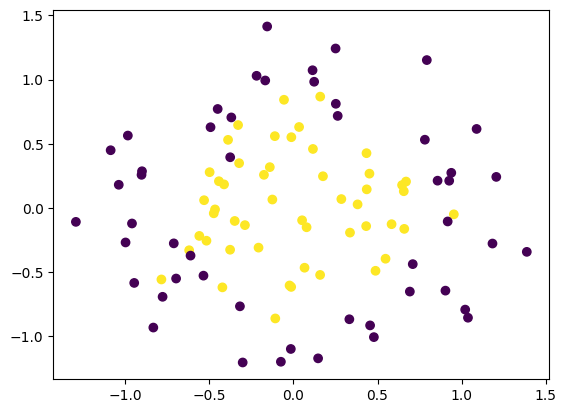

In [ ]:
from sklearn.datasets import make_circles

x, y = make_circles(noise=.2, factor=.5)
plt.scatter(x[:,0], x[:,1], c=y)

The "yellow" group appears concentrated around a mean of zero. The purple group also shows a consistent and not at all scattered distribution, more external compared to the first group. There does not seem to be a line capable of separating the two groups.

We can opt for **non-linear classification models**, such as the **Decision Tree**. This model is indeed well-suited to classification problems in **high-dimensional settings**, where many features are observed.

Let's first test a simple **Logistic Regression** model.

The baseline Logistic Regression model.


In [ ]:
# Define the model pipeline
logistic_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(class_weight="balanced", max_iter=1000))
])

# Perform cross-validation on the training set
cv_scores = cross_val_score(logistic_pipeline, x_train, y_train, cv=5, scoring='accuracy')
print(f"Cross-validation scores: {cv_scores}")
print(f"Mean cross-validation score: {cv_scores.mean():.4f}")


Cross-validation scores: [0.85903335 0.85846349 0.85926254 0.8584605  0.86017012]
Mean cross-validation score: 0.8591


Cross-validation is a technique used to evaluate the performance of a model. It involves dividing the dataset into n subsets and testing the model n times, each time using a different subset as the test set and the remaining n-1 subsets as the training set. Finally, the average of the performance metrics obtained in each iteration is calculated.

We use class_weight="balanced" to address the imbalanced target classes.

We observe a Mean cross-validation score: 0.8591.

This type of model achieves a non-negative, but improvable evaluation for optimally describing the observations of the distribution.

Decision Tree Model

In [ ]:
pipeline = Pipeline(steps=[
    ('classifier', DecisionTreeClassifier(criterion="gini"))
])

cv_scores = cross_val_score(pipeline, x_train, y_train, cv=5, scoring='accuracy')
print(f"Cross-validation scores: {cv_scores}")
print(f"Mean cross-validation score: {cv_scores.mean():.4f}")

pipeline.fit(x_train, y_train)

# Check the depth of the tree
depth_of_tree = pipeline.named_steps['classifier'].get_depth()
print(f"Depth of the tree: {depth_of_tree}")

Cross-validation scores: [0.94803715 0.94696074 0.94719179 0.94695962 0.94841596]
Mean cross-validation score: 0.9475
Depth of the tree: 55


We notice that the evaluations have improved significantly.

Mean cross-validation score: 0.9475.


The decision tree has 55 levels of depth.

We set the hyperparameter max_depth to 30 to limit the depth and test cross-validation again.


In [ ]:
pipeline = Pipeline(steps=[
    ('classifier', DecisionTreeClassifier(criterion="gini", max_depth=30))
])

cv_scores = cross_val_score(pipeline, x_train, y_train, cv=5, scoring='accuracy')
print(f"Cross-validation scores: {cv_scores}")
print(f"Mean cross-validation score: {cv_scores.mean():.4f}")

pipeline.fit(x_train, y_train)

depth_of_tree = pipeline.named_steps['classifier'].get_depth()
print(f"Depth of the tree: {depth_of_tree}")

Cross-validation scores: [0.95278599 0.9528282  0.95272167 0.95158192 0.95373478]
Mean cross-validation score: 0.9527
Depth of the tree: 30


The results have further improved.

Mean cross-validation score: 0.9527 (from 0.9475).

Since we observed that the target variable has highly imbalanced classes (0: 91.22%; 1: 8.78%), we attempt to further optimize the model using UnderSampling with a threshold value of 0.7. This threshold means that predictions with a probability of 70% or higher will be considered as belonging to the positive class (creditworthy), thereby balancing the significant imbalance of the positive class relative to the negative class.

In [ ]:
# Define the pipeline with undersampling and classifier
pipeline = Pipeline(steps=[
    ('undersample', RandomUnderSampler(sampling_strategy=0.2, random_state=42)),
    ('classifier', DecisionTreeClassifier(criterion="gini", max_depth=30))
])

pipeline.fit(x_train, y_train)

# Check the new dimensions of the training set after undersampling
x_train_resampled, y_train_resampled = pipeline.named_steps['undersample'].fit_resample(x_train, y_train)
print("Dimensioni del set di training dopo l'undersampling:")
print(f"x_train_resampled: {x_train_resampled.shape}")
print(f"y_train_resampled: {y_train_resampled.shape}")

y_proba = pipeline.named_steps['classifier'].predict_proba(x_test)[:, 1]

# Threshold value
threshold = 0.70
y_pred_custom = (y_proba >= threshold).astype(int)

# Calculate accuracy on the training and test sets
accuracy_train = accuracy_score(y_train_resampled, pipeline.named_steps['classifier'].predict(x_train_resampled))
accuracy_test = accuracy_score(y_test, y_pred_custom)

print(f"Accuracy: train={accuracy_train:.4f} test={accuracy_test:.4f}")
print(classification_report(y_test, y_pred_custom))

# Confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred_custom)
print(conf_matrix)

Dimensioni del set di training dopo l'undersampling:
x_train_resampled: (124830, 26)
y_train_resampled: (124830,)
Accuracy: train=0.9670 test=0.9567
              precision    recall  f1-score   support

           0       0.99      0.96      0.98     92612
           1       0.70      0.90      0.78      8917

    accuracy                           0.96    101529
   macro avg       0.84      0.93      0.88    101529
weighted avg       0.96      0.96      0.96    101529

[[89132  3480]
 [  913  8004]]


In the evaluation metrics, the **Target class 1** represents the **positives**, meaning the observations considered creditworthy, while class **0** identifies the **negatives**, i.e., the observations deemed not creditworthy.

The model shows excellent performance:

* **Confusion Matrix**: highlights a well-balanced classification:

  * True negatives: 89,132
  * True positives: 8,004
  * False negatives: 913
  * False positives: 3,480

* **Accuracy**: measures the overall percentage of correct classifications.

* **Precision**: calculated as *true positives / (true positives + false positives)*.
  This is particularly useful when the cost of false positives is high, such as in commercial offers addressed only to genuinely interested customers.

* **Recall**: given by *true positives / (true positives + false negatives)*.
  This is important when the cost of false negatives is critical, as in early cancer diagnosis.

* **F1 Score**: represents the harmonic mean between precision and recall, useful in the presence of imbalanced classes.

The metrics indicate a stronger ability of the model to correctly predict negatives (class 0 precision: 99%; class 0 recall: 96%) compared to positives (class 1 precision: 70%; class 1 recall: 90%).

The F1 score confirms this balance: 98% on negatives and 78% on positives, highlighting a very solid overall performance, with a slight tendency toward assigning class 0.


### CONCLUSIONS

The model demonstrates strong predictive capabilities, successfully identifying the target in the most sensitive areas and adapting through targeted recalibrations. It is indeed possible to steer the model's predictions toward greater focus on negative areas, supporting risk management, or toward expanding commercial opportunities by increasing the propensity to grant credit. Between these two directions, the model shows a preference for the former.

The estimates produced allow us to understand which characteristics most influence the assessment of a customer's creditworthiness and the consequent offer of credit products.

Overall, the model exhibits high accuracy, accompanied by a marked conservative attitude in risk evaluation.

# EXPLANATORY MODELLING WITH SHAP

In the initial phase of the project, we used **Pearson correlation** to identify direct relationships between the variables and the target. This method revealed that variables such as **AMT_INCOME (annual income)**, **YEARS_BIRTH (customer age)**, and **DAYS_EMPLOYED (actual employment duration)** show strong linear relationships with customer reliability and the likelihood of being granted a credit card.

However, Pearson only detects **simple linear relationships** and **does not account for interactions between variables**, nor for how these influence the model’s actual decisions.

For this reason, it is essential to introduce an Explainable AI approach such as **SHAP**, which makes it possible to analyze **the complex interdependencies between variables**, explaining how each feature contributes to predictions in a specific decision-making context—**taking into account the complexity and structure of the model**.

This combination of tools enables a shift from a statistical view to a model-based interpretation of the variables, providing more complete and reliable insights to guide project improvements and refine results for strategic decision-making.

**Shap Summary Plot**

A plot showing the average absolute impact of the variables for the positive class (TARGET = 1, i.e., creditworthy customers) within the model.

In [ ]:
# Get original column names from df excluding the target column
feature_names = df.drop("TARGET", axis=1).columns.tolist()

# Convert x_test to DataFrame if it isn't one (e.g. array)
X_test_df = pd.DataFrame(x_test)

# Stratified sampling to obtain a balanced subset
sample_size = min(1000, len(X_test_df))
X_test_sampled, _, y_test_sampled, _ = train_test_split(
    X_test_df, y_test,
    test_size=len(X_test_df) - sample_size,
    stratify=y_test,
    random_state=42
)

# Reassign correct column names (if X_test_df had numbered columns)
X_test_sampled = pd.DataFrame(X_test_sampled.values, columns=feature_names)

SHAP type: <class 'numpy.ndarray'>
SHAP shape: (1000, 26, 2)


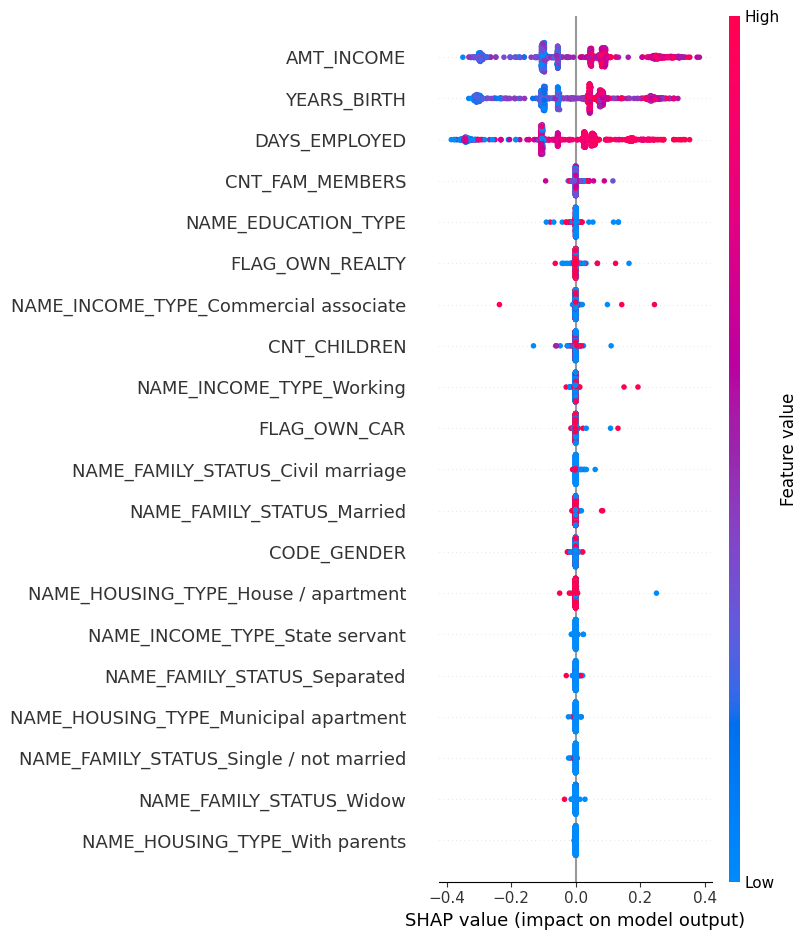

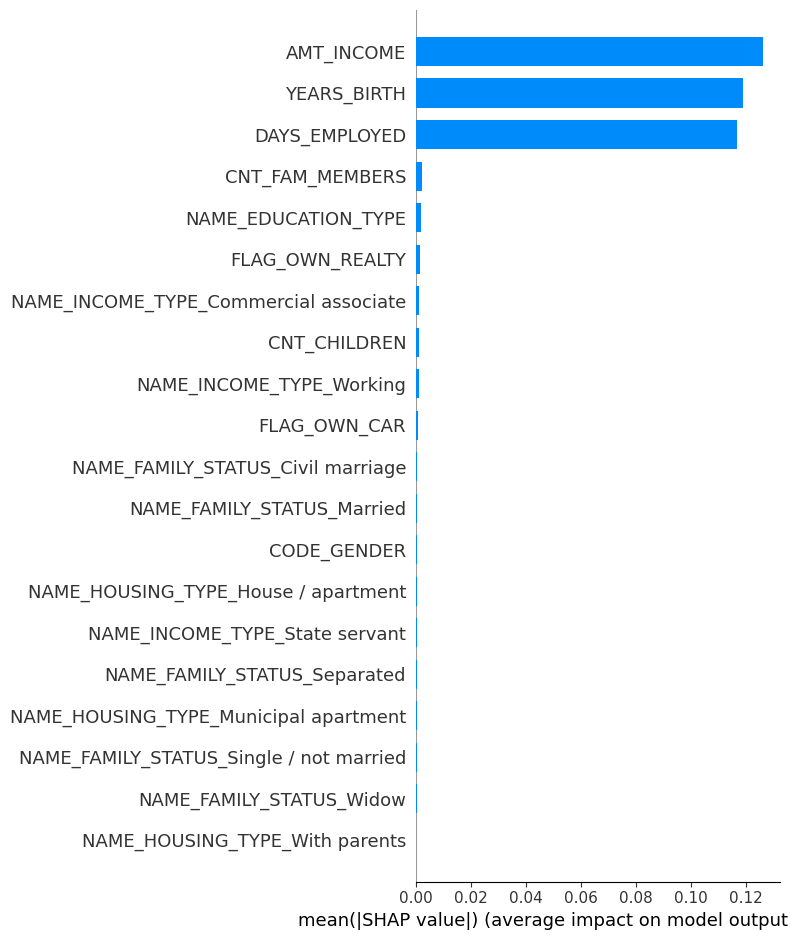

In [ ]:
import shap

# Extract the model from the pipeline
tree_model = pipeline.named_steps['classifier']

# Create the SHAP explainer
explainer = shap.TreeExplainer(tree_model)

# Compute SHAP values on the sample with correct column names
shap_values = explainer.shap_values(X_test_sampled)

# Basic diagnostics
print(f"SHAP type: {type(shap_values)}")
print(f"SHAP shape: {np.shape(shap_values)}")

# Handling shap_values with possible 3D array (samples, features, classes)
if isinstance(shap_values, np.ndarray) and shap_values.ndim == 3 and shap_values.shape[2] == 2:
    # SHAP values for the positive class (index 1)
    shap_values_class1 = shap_values[:, :, 1]
    shap.summary_plot(shap_values_class1, X_test_sampled)
    shap.summary_plot(shap_values_class1, X_test_sampled, plot_type="bar")
elif isinstance(shap_values, list) and len(shap_values) == 2:
    # Case of list with 2 arrays (binary classes)
    shap.summary_plot(shap_values[1], X_test_sampled)
    shap.summary_plot(shap_values[1], X_test_sampled, plot_type="bar")
else:
    # Generic case (e.g. regression or single matrix)
    shap.summary_plot(shap_values, X_test_sampled)
    shap.summary_plot(shap_values, X_test_sampled, plot_type="bar")

### CONSIDERATIONS

We observe that the **3 most influential variables according to SHAP** are:

* **AMT_INCOME**: **Annual income is the most impactful variable according to SHAP**, consistent with the Pearson analysis (27% correlation). The model uses it to distinguish between customers with greater or lesser repayment capacity. Higher values reduce the risk of default.

* **YEARS_BIRTH**: **The customer’s age plays a key role**, also aligned with Pearson (18%). SHAP shows that older customers tend to be considered more reliable by the model.

* **DAYS_EMPLOYED**: **Employment seniority is a strong predictor**, also consistent with Pearson results (22%). Higher values reduce risk.

Key observations:

* These three variables had already been identified as relevant in the correlation analysis, and SHAP confirms that **they are indeed central to the predictive process**.

* Although less influential, other important variables with a stabilizing effect on risk according to SHAP — but **not among the features identified by Pearson** — include:

  * **CNT_FAM_MEMBERS**: Number of household members.  
  * **NAME_EDUCATION_TYPE**: Education level.  
  * **FLAG_OWN_REALTY** and **FLAG_OWN_CAR**: Indicators of real estate and car ownership, likely capturing the ability to manage recurring expenses and credit obligations.

  **These variables highlight an interesting discrepancy between the statistical metric and the model’s impact.** In fact, despite lacking strong linear correlation with the target, they are important in the model, suggesting that **the model effectively learns patterns that do not emerge from simple linear correlations between variables, but are instead the result of their interactions.**


**SHAP Dependence Plot**

First plot - the plot combines the first and second variables to highlight their interaction in the model’s predictive process.

Most important features according to SHAP: AMT_INCOME (1st), YEARS_BIRTH (2nd)


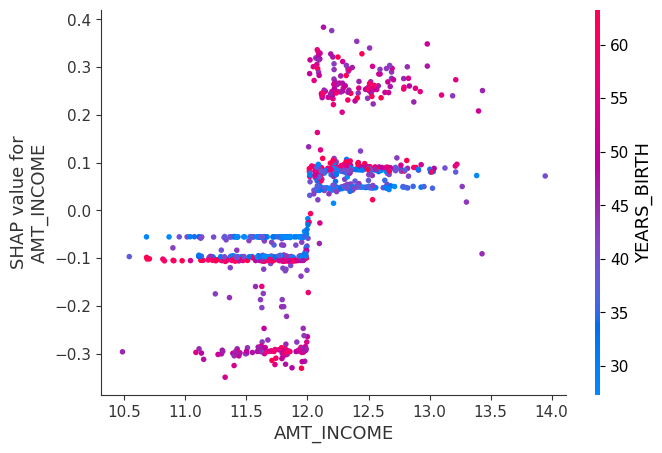

In [ ]:
# Ensure shap_values correspond to the positive class
if isinstance(shap_values, np.ndarray) and shap_values.ndim == 3 and shap_values.shape[2] == 2:
    shap_values_to_plot = shap_values[:, :, 1]
elif isinstance(shap_values, list) and len(shap_values) == 2:
    shap_values_to_plot = shap_values[1]
else:
    shap_values_to_plot = shap_values

# Compute mean absolute importance for each feature
mean_abs_shap = np.abs(shap_values_to_plot).mean(axis=0)

# Sort features by importance
feature_order = np.argsort(-mean_abs_shap)
top1 = X_test_sampled.columns[feature_order[0]]
top2 = X_test_sampled.columns[feature_order[1]]

# Display feature names
print(f"Most important features according to SHAP: {top1} (1st), {top2} (2nd)")

# Dependence plot: top1 vs color-coded top2
shap.dependence_plot(top1, shap_values_to_plot, X_test_sampled, interaction_index=top2)

# CONSIDERATIONS

The **SHAP Dependence Plot** shows the effect of the variable `AMT_INCOME` (the most important according to SHAP) in interaction (color-coded) with `YEARS_BIRTH` (the second most relevant).

* **X-Axis**: Values of the variable `AMT_INCOME` (logarithmic), representing the customer’s annual income.
* **Y-Axis**: SHAP value, indicating how much each income level contributes to the probability that the customer is creditworthy (`TARGET = 1`).
* **Color**: `YEARS_BIRTH`, from younger (blue) to older (dark red).

---

### Interpretation

* A **clear discontinuity is observed around the value of AMT_INCOME ≈ 12** (which corresponds to about 150,000 in the original scale of the variable, which has undergone a log transformation):

  * Below this point, SHAP values are generally negative, indicating that low income **reduces the probability of being classified as creditworthy**.
  * Above this point, SHAP values tend to become positive, **especially for older customers**.

* Therefore, **income has a positive impact only beyond a certain threshold**, and this effect is **modulated by age**:

  * **Older customers with high income** are consistently evaluated positively.
  * **Younger customers with high income** show more dispersion in terms of impact, suggesting that **age reinforces the predictive value of income**.

---

### Resulting Actions

* The **net threshold on AMT_INCOME** can be integrated into business logic: below a certain point, even small income increases do not improve reliability; above that point, a clear jump in contribution is observed.
* A **segmentation of the analysis by age groups** can be explored, to better understand how minimum required income thresholds vary depending on life cycle stages.
* Finally, this insight could **inform credit marketing or pricing strategies**, to differentiate conditions and offers based on the combined age-income profile.


**Second SHAP Dependence Plot** — the plot combines the first and third variables to highlight their interaction in the model’s predictive process.

Features selected for dependence plot: AMT_INCOME (1st), DAYS_EMPLOYED (3rd)


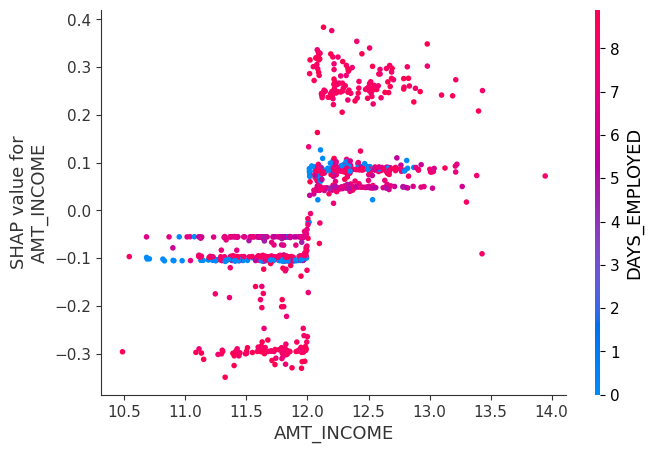

In [ ]:
# Ensure shap_values correspond to the positive class
if isinstance(shap_values, np.ndarray) and shap_values.ndim == 3 and shap_values.shape[2] == 2:
    shap_values_to_plot = shap_values[:, :, 1]
elif isinstance(shap_values, list) and len(shap_values) == 2:
    shap_values_to_plot = shap_values[1]
else:
    shap_values_to_plot = shap_values

# Compute mean absolute importance for each feature
mean_abs_shap = np.abs(shap_values_to_plot).mean(axis=0)

# Sort features by decreasing importance
feature_order = np.argsort(-mean_abs_shap)
top1 = X_test_sampled.columns[feature_order[0]]
top3 = X_test_sampled.columns[feature_order[2]]

# Display selected feature names
print(f"Features selected for dependence plot: {top1} (1st), {top3} (3rd)")

# Dependence plot: top1 vs color-coded top3
shap.dependence_plot(top1, shap_values_to_plot, X_test_sampled, interaction_index=top3)

# CONSIDERATIONS

This second **SHAP dependence plot** shows the relationship between the variable `AMT_INCOME` (declared annual income) and the **interaction variable `DAYS_EMPLOYED`** (employment duration in years, log-scaled), the third most important according to SHAP.

* **X-Axis**: `AMT_INCOME` transformed to a logarithmic scale.  
* **Y-Axis**: SHAP value of `AMT_INCOME`, i.e., the contribution of this variable to the classification of the customer as reliable (`TARGET = 1`).  
* **Color**: `DAYS_EMPLOYED`, ranging from 0 to 8 (more recent employment in blue, more stable in red).

---

### Interpretation

* Consistent with the previous analysis, it confirms that **income (`AMT_INCOME`) has a non-linear effect**:

  * For values below **approximately 12** (i.e., incomes under ~150,000 in the log-transformed scale), SHAP values are generally **negative**, indicating a **lower probability of being considered creditworthy**.
  * Beyond this threshold, SHAP values rise and become **positive**, indicating a favorable effect on creditworthiness prediction.

* The interaction with `DAYS_EMPLOYED` shows that:

  * **At equal income levels**, customers with **longer employment duration** (red) tend to have higher SHAP values — meaning the model considers them more creditworthy.
  * This effect is more visible for those with medium-high incomes (between 12 and 13).

---

### Operational Insight

* This pattern can be leveraged to strengthen creditworthiness segmentation:

  * **Medium-high income and stable employment** emerge as a combination that the model considers favorable.

* Possible **actions**:

  * Integrate these thresholds into automatic pre-approval rules within customer acquisition processes.
  * Investigate potential **threshold effects** within the current customer portfolio.


## **Final Conclusions**

During the project, two tools were compared to analyze the role of variables in prediction: **Pearson correlation** and **SHAP evaluations**:

- **Pearson** assesses the linear correlation between variables, offering an initial indication of their relationship with the target.
- **SHAP** quantifies the **impact of variables within the predictive model**, accounting for non-linearity, interactions, and thresholds.

These two perspectives are complementary: Pearson supports the preliminary feature selection, while SHAP allows for understanding how and when each variable is actually used by the model.

SHAP confirms the importance of the variables already identified by Pearson — Annual income, Age, and Employment duration — but reveals also **non-linear nature** and **interactions among features** through Dependence Plots:

- **AMT_INCOME + YEARS_BIRTH**:  
  Income has a positive impact only beyond a critical threshold (log ~12 ≈ 150,000), and the effect is stronger for older customers.

- **AMT_INCOME + DAYS_EMPLOYED**:  
  Employment stability reinforces the positive impact of income.

---

### **3. Ethical and Strategic Considerations**

- **Bias and Transparency**:  
  SHAP analysis showed that socio-demographic variables such as Age and Employment stability can amplify the impact of Income.  
  This may introduce indirect bias against younger clients or those with unstable jobs, even with equal income.  
  To properly guide the identification of thresholds and determining factors in predictions, it is necessary to critically assess the historical data or enrich it with complementary variables that work in synergy. This approach allows for better representation of fragile profiles and promotes their inclusion.

- **Operational Strategies**:  
  Combinations like medium-high income + high employment duration represent virtuous clusters the model identifies as reliable. These insights can support:
  - automatic pre-approval policies;
  - commercial targeting of high-potential profiles;
  - definition of operational thresholds to integrate into pricing or approval logic.

---

### **4. Final Summary**

**The integration of statistical analysis (Pearson) and model-based analysis (SHAP)** allowed for validation of preliminary variable choices and identification of complex patterns and non-linear interactions, **highlighting potential ethical risks, opportunities for data enhancement or reshaping, and strategic advantages**.

Understanding this synergy makes it possible to **build more interpretable, robust, and responsible models, ready to support transparent, personalized, and strategically effective operational decisions**.